BrM Nanostring Cosmx 6k (36 Samples, 3M cells)
=======================

In [ ]:
# ==============================================================================
# CosMx Brain Metastasis Spatial Transcriptomics
# ==============================================================================
# %pwd

# 加载相关工具包
from pathlib import Path
import pandas as pd
pd.set_option("display.max_columns", None)

import numpy as np
import os
import matplotlib.pyplot as plt
import palantir
import warnings
import gc
import pickle
import random
import torch

import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity


import anndata as ad

from scipy.stats import gaussian_kde, entropy
from scipy.sparse import csr_matrix
import seaborn as sns

import sklearn
print(sklearn.__version__)  # 应输出 1.3.2

import scanpy as sc
import pyucell as uc

# pip install squidpy==1.3.1 scanpy==1.9.3 anndata==0.9.0 numpy==1.23.5 scipy==1.9.3 pandas==1.5.3 scikit-image==0.19.3 tifffile==2022.10.10 pillow==9.4.0 matplotlib==3.6.3 seaborn==0.12.2 numba==0.56.4 networkx==2.8.8 scikit-learn==1.2.2 statsmodels==0.13.5 omnipath==1.0.7   # 旧版 squidpy 才可以读入 
import squidpy as sq
print(sq.__version__)

import celltypist

# from napari_spatialdata import Interactive
import spatialdata as sd
import spatialdata_io

from scipy.spatial import distance_matrix
from collections import defaultdict

from statannotations.Annotator import Annotator
from itertools import combinations  # 自动生成所有两两配对

warnings.filterwarnings('ignore')
sc.logging.print_header()


1.9.0
1.8.1


/home/dingrong/miniconda3/envs/R453/lib/python3.14/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


Package,Version
pandas,2.3.3
numpy,2.4.3
matplotlib,3.10.9
palantir,1.4.4
torch,2.11.0 (2.10.0)
networkx,3.6.1
scikit-learn,1.9.0
anndata,0.12.16
scipy,1.17.1
seaborn,0.13.2


In [2]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


In [3]:
ad.settings.allow_write_nullable_strings = True  # 开启允许保存字符串类型

fig_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result"
# fig_dir = Path().resolve() / "BM_Cosmx_Py"/"Result"
os.makedirs(fig_dir, exist_ok=True)

# ===================== PLOT SETTINGS =====================
sc.set_figure_params(
	facecolor="white", figsize=(6,6), dpi=300, fontsize=11, frameon=True
)
sc.settings.verbosity = 3
sc.settings.n_jobs = 16
sc.settings.figdir = fig_dir

plt.rcParams["savefig.dpi"] = 300
# plt.rcParams["save.bbox_inches"] = "tight"
plt.rcParams['axes.unicode_minus'] = False


# ===================== UTILITY FUNCTIONS =====================
def save_fig(name, fig_dir):
	plt.savefig(os.path.join(fig_dir, f"{name}.png"), dpi=300, bbox_inches="tight" )
	plt.savefig(os.path.join(fig_dir, f"{name}.pdf"), dpi=300, bbox_inches="tight" )
	# plt.close()

# 自动缩放空间坐标
def auto_scale_spatial(adata, target_scale=1000):
	"""
	自动将空间坐标缩放到 [0, target_scale] 范围
	"""
	x = adata.obsm["spatial"][:, 0]
	y = adata.obsm["spatial"][:, 1]
	# 缩放到 0~1
	x = (x - x.min()) / (x.max() - x.min())
	y = (y - y.min()) / (y.max() - y.min())
	# 放大到目标范围
	x = x * target_scale
	y = y * target_scale
	# 放回
	adata.obsm["spatial"] = np.column_stack([x, y])

def plot_umap_spatial(adata, color_key, fig_dir, suffix=""):
	sc.pl.umap(adata, color=color_key, show=False)   # , save=f"umap_{color_key}{suffix}"
	save_fig(f"umap.{color_key}{suffix}", fig_dir)
	for sid in sample_list:
		sub = adata[adata.obs["sample"] == sid].copy()
		if sub.n_obs < 50:
			continue
		# 修复空间坐标
		# sub.obsm["spatial"] = sub.obs[["CenterX_global_px", "CenterY_global_px"]].values  # 直接提取坐标画出来图是反的，CosMx 仪器：Y 轴向下增大（图像坐标系，左上角为原点）， Matplotlib/squidpy：Y 轴向上增大（数学坐标系，左下角为原点）
		# ✅ 永久翻转 Y 坐标
		x = sub.obs["CenterX_global_px"].values
		y = sub.obs["CenterY_global_px"].values
		y_flipped = y.max() + y.min() - y
		sub.obsm["spatial"] = np.column_stack([x, y_flipped])
		# 即使有 obsm["spatial"]，squidpy 依然会强制检查 adata.uns["spatial"], 强制添加 squidpy 必须要的空结构，解决 KeyError
		sub.uns["spatial"] = {"images": {}}
		# # 自动缩放你的 sub 数据坐标
		# auto_scale_spatial(sub, target_scale=1000)
		# sq.pl.spatial_scatter(sub, color=color_key, size=1, img=False, frameon=False, shape=None)  # , library_key="fov" , palette="tab20" , save=f"spatial.{color_key}.{sid}.{suffix}" # img=False, NanoString CosMx 数据，没有组织病理学图像（H&E）
		sq.pl.spatial_scatter(sub, color=color_key, size=1, img=False, frameon=False, legend_fontsize=4, shape=None)  # , library_key="fov" , save=f"spatial.{color_key}.{sid}.{suffix}"  , squidpy 中 legend_loc 只能填：right / left / top / bottom / center ,  scanpy 支持 legend_loc='outside right'
		# ax.invert_yaxis()  # ✅ 临时翻转 Y 轴，匹配 CosMx 原始图像
		save_fig(f"spatial_{color_key}.{sid}{suffix}", fig_dir)

def plot_enrich_bar(df, x_col, y_col, title, name, fig_dir, topn=15):
	plt.figure(figsize=(10,6))
	df_top = df.head(topn).sort_values(x_col, ascending=True)
	sns.barplot(data=df_top, x=x_col, y=y_col)
	plt.title(title, fontsize=12)
	plt.tight_layout()
	save_fig(name, fig_dir)

def plot_boxplot(df, cols, name, fig_dir, title=""):
	plt.figure(figsize=(10,6))
	ax = df[cols].boxplot(grid=False)
	ax.grid(False)  # 去掉网格线
	plt.title(title)
	plt.tight_layout()
	save_fig(name, fig_dir)

样本信息
---------------------------------------------

In [ ]:
# ===================== GLOBAL CONFIG =====================
project_name = "BM_Cosmx_Py"
out_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result/"
# out_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result.bk/"
fig_dir = os.path.join(out_dir, "figures")
csv_dir = os.path.join(out_dir, "tables")
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)

In [ ]:

adata = sc.read_h5ad(os.path.join(out_dir, f"{project_name}.h5ad"))
adata


【Step 11】 Spatial Distribution and Neighborhood Enrichment Analysis ( 用固定的细胞邻居数目 n_neighs=6)
---------------------------------------------

In [ ]:

# ==============================================================================
# METHODS: 11. Spatial Distribution and Neighborhood Enrichment Analysis  ( 用固定的细胞邻居数目 n_neighs=6)
# Detailed Description: Spatial cellular architecture was comprehensively profiled 
# using Squidpy spatial analysis tools to map cell type distributions across 
# histological sections. Cell-type co-occurrence analysis was performed to identify 
# non-random spatial associations between cellular populations. Neighborhood 
# enrichment statistics were computed to quantify significant spatial interactions, 
# while multi-parameter overlay plots integrated transcriptomic, phenotypic, and 
# spatial data at single-cell resolution to delineate the structural organization 
# of the metastatic brain tumor microenvironment.
# ==============================================================================
print("\n【Step 11】 Spatial Distribution and Neighborhood")
fig_dir = os.path.join(out_dir, "Step11_Distribution", "N_neighs_6")
csv_dir = os.path.join(out_dir, "Step11_Distribution", "N_neighs_6")
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)



【Step 11】 Spatial Distribution and Neighborhood


In [ ]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


In [ ]:
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity

# ------------------
# 图 4｜细胞类型 Neighborhood Enrichment 网络图（带颜色+节点大小正比于细胞数量）
# ------------------

# 节点大小：细胞数量越多，节点越大
# 节点颜色：细胞类型区分
# 连线粗细：互作强度，越粗越强
# 连线长短：算法画图效果，无生物学意义 

import math

# 图 4｜细胞类型 Neighborhood Enrichment 网络图（带颜色+节点大小正比于细胞数量）
print("正在绘制：细胞 Neighborhood Enrichment 网络")

# 加载已经存好的数据
enrich_dict = adata.uns["all_sample_enrichment_zscore"]
cell_types = adata.obs["CellType"].cat.categories.dropna()
sample_to_type = adata.obs.groupby("sample")["Type"].first()
# 真正参与计算的类型
first_df = next(iter(enrich_dict.values()))
used_cell_types = first_df.index.tolist()  

# 计算细胞类型数量（用于节点大小）
cell_count = adata.obs['CellType'].value_counts().to_dict()  # 用你的sub/adata都行


# 计算方法三：【细胞级别加权】按细胞数量加权平均 
# 每个样本 × 每种细胞 的数量
sample_cell_count = adata.obs.groupby(['sample', 'CellType']).size().unstack(fill_value=0)
# 计算平均矩阵
n_ct = len(used_cell_types)
mean_all = np.zeros((n_ct, n_ct))
# 对 每个细胞对 (i -> j) 单独加权平均
for i, ct_center in enumerate(used_cell_types):
	# 收集所有样本在这个【中心细胞】上的 enrichment 分数
	scores = []
	weights = []
	for sid, df in enrich_dict.items():
		# 取出该样本：ct_center → 所有细胞 的分数
		if ct_center in df.index:
			score = df.loc[ct_center, used_cell_types].values
			score = np.nan_to_num(score, nan=0.0, posinf=0.0, neginf=0.0)
		else:
			score = np.zeros(n_ct)
		# 权重 = 该样本中【这个中心细胞 ct_center 的数量】
		w = sample_cell_count.loc[sid, ct_center] if ct_center in sample_cell_count.columns else 0
		if w > 0:  # 只有细胞存在时才加入
			scores.append(score)
			weights.append(w)
	# 对这个中心细胞，做【细胞数量加权平均】
	if len(scores) > 0:
		mean_all[i, :] = np.average(scores, axis=0, weights=weights)
# 最终矩阵
mean_all = np.nan_to_num(mean_all, nan=0.0, posinf=0.0, neginf=0.0)
mean_df = pd.DataFrame(mean_all, index=used_cell_types, columns=used_cell_types)
mean_z = mean_all

# 阈值过滤
threshold = np.percentile(mean_z[mean_z > 0], 0)  # 只保留前 100% 强连接
# threshold = np.percentile(mean_z[mean_z > 0], 50)  # 只保留前 50% 强连接
G = nx.Graph()
for i, ct1 in enumerate(cell_types):
	for j, ct2 in enumerate(cell_types):
		if i < j and mean_z[i, j] > threshold:
			G.add_edge(ct1, ct2, weight=mean_z[i, j])
# 布局
pos = nx.spring_layout(G, k=1, iterations=500, threshold=1e-4, seed=1234)
# pos = nx.fruchterman_reingold_layout(G, k=3.5, iterations=500, threshold=1e-4, seed=1234)  # k=3.5, 节点之间的距离：越大越散开 # iterations=500, 迭代次数：越大布局越美观 # seed=42 固定随机，每次图一样（可复现）
# 颜色匹配 CellType
cell_type_list = list(G.nodes())
color_map = []
for ct in cell_type_list:
	idx = np.where(adata.obs['CellType'].cat.categories == ct)[0][0]
	color_map.append(adata.uns['CellType_colors'][idx])
# 节点大小（数量成比例）
# node_size = [cell_count.get(ct, 100) * 0.8 for ct in G.nodes()]
# node_size = [min(max(50, cell_count.get(ct, 1) * 0.15), 1800) for ct in G.nodes()] # 简单安全版
# 稳定版（对数缩放 + 封顶，绝不巨大、绝不遮盖）
min_size = 150    # 最小节点
max_size = 2500   # 最大节点（不超标）
node_size = []
for ct in G.nodes():
	cnt = cell_count.get(ct, 1)
	# 平方根：比 log 区分度更大，但依然可控
	size = min_size + math.sqrt(cnt) * 8  
	size = min(size, max_size)  # 绝不超过上限
	node_size.append(size)

# 绘图
plt.figure(figsize=(12, 12))
nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=node_size, alpha=0.9, edgecolors="white", linewidths=2)
# 连线粗细 = 互作强度
nx.draw_networkx_edges(G, pos, width=[G[u][v]['weight'] * 0.3 for u, v in G.edges()], alpha=0.6, edge_color="gray")
# 标签
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
plt.grid(False)
plt.axis("off")
plt.title("Cell-Type Spatial Neighborhood Enrichment Network", fontweight="bold")
plt.tight_layout()
save_fig("cell_Neighborhood_Enrichment_network", fig_dir)
# plt.close()



正在绘制：细胞 Neighborhood Enrichment 网络
正在按 Type 分组绘制细胞互作网络...
→ 正在绘制: IP
→ 正在绘制: KP


正在绘制：全体样本 定向共现网络
正在按 Type 分组绘制 定向共现网络
→ 绘制: IP
→ 绘制: KP


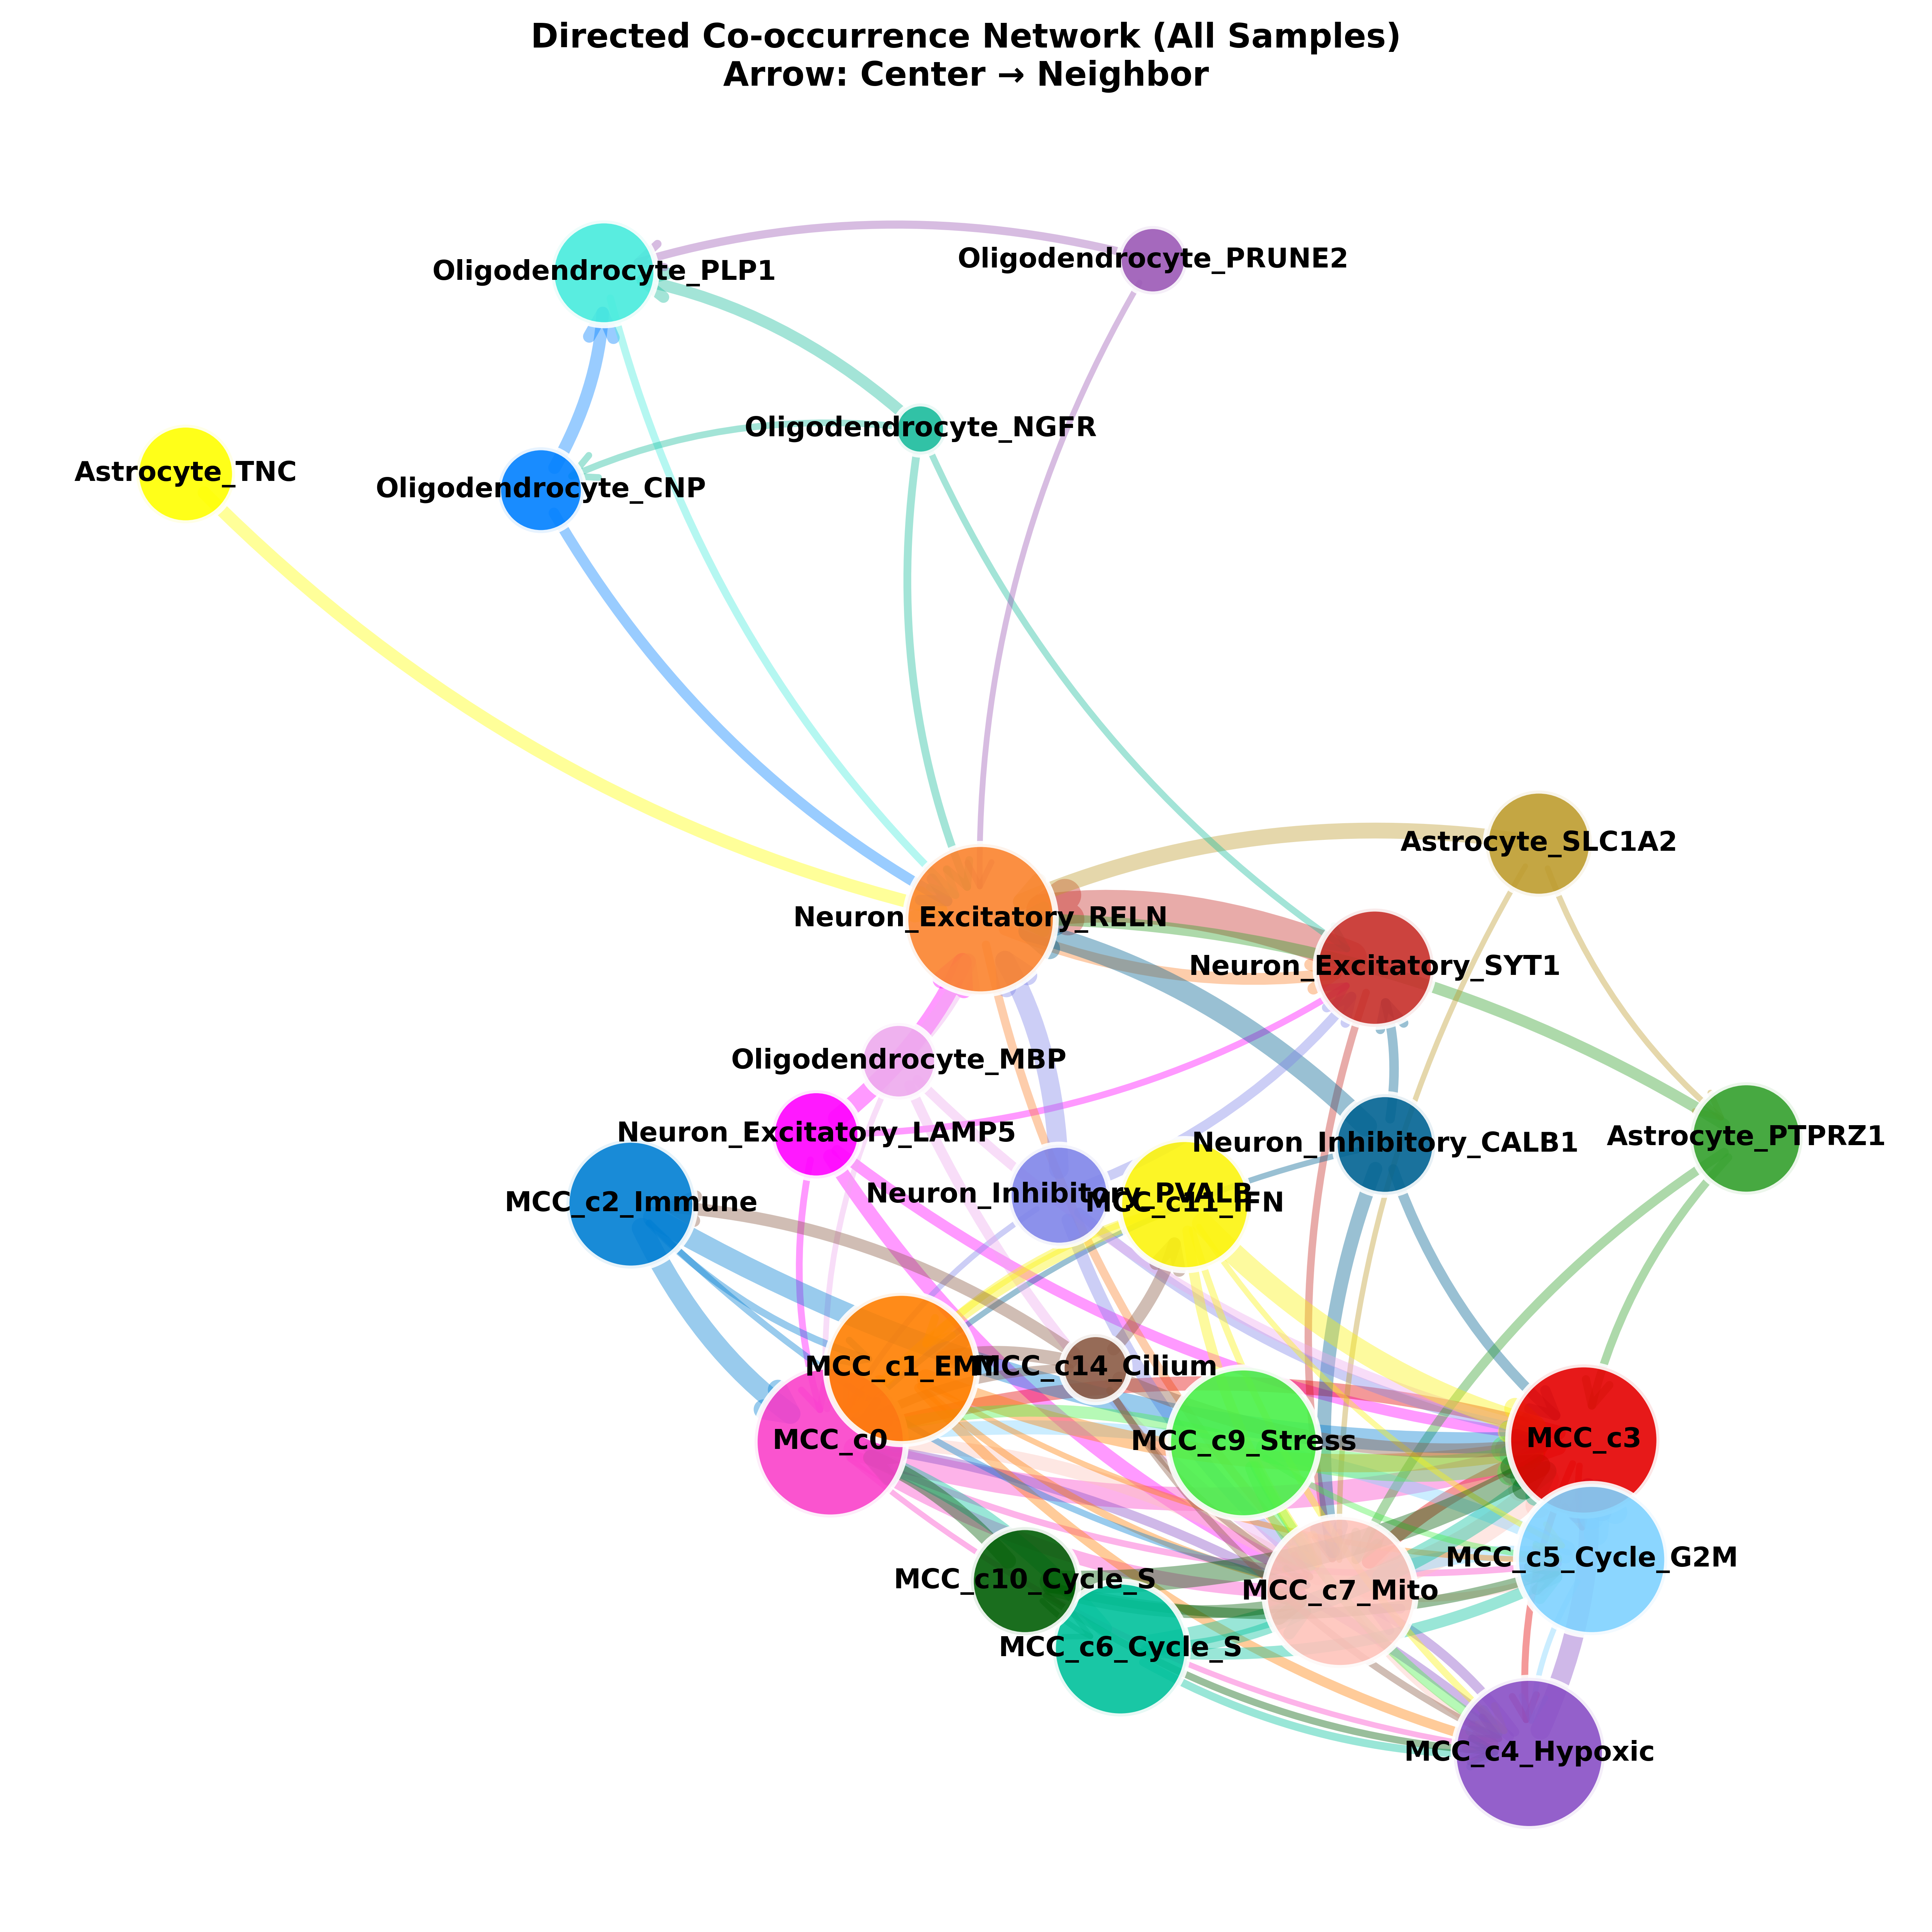

In [ ]:
# A → B 表示：B 经常出现在 A 的周围, A 被 B 包围
# 为了更清晰 ，只画部分细胞类型

# ------------------
# 定向共现 网络图（Directed Co-occurrence Network with ARROWS）
# ------------------
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math


# ------------------
# 图 4｜细胞类型 定向共现网络（带颜色+节点大小正比于细胞数量）
# ------------------
# 全体样本 定向共现网络 
print("正在绘制：全体样本 定向共现网络")

# 加载已经存好的数据
directed_dict = adata.uns["all_sample_directed_cooccurrence"]
cell_types = adata.obs["CellType"].cat.categories.dropna()
sample_to_type = adata.obs.groupby("sample")["Type"].first()
first_df = next(iter(directed_dict.values()))
# used_cell_types = first_df.index.tolist()
used_cell_types = ["Neuron_Excitatory_LAMP5", "Neuron_Excitatory_RELN", "Neuron_Excitatory_SYT1", "Neuron_Inhibitory_CALB1", "Neuron_Inhibitory_PVALB", "Astrocyte_PTPRZ1", "Astrocyte_SLC1A2", "Astrocyte_TNC", "Oligodendrocyte_CNP", "Oligodendrocyte_MBP", "Oligodendrocyte_NGFR", "Oligodendrocyte_PLP1", "Oligodendrocyte_PRUNE2", "MCC_c0", "MCC_c1_EMT", "MCC_c2_Immune", "MCC_c3", "MCC_c4_Hypoxic", "MCC_c5_Cycle_G2M", "MCC_c6_Cycle_S", "MCC_c7_Mito", "MCC_c9_Stress", "MCC_c11_IFN", "MCC_c10_Cycle_S", "MCC_c14_Cilium"]
# 计算细胞类型数量（用于节点大小）
sample_cell_counts = adata.obs["sample"].value_counts().to_dict()
# 计算细胞类型数量（用于节点大小）
cell_count = adata.obs['CellType'].value_counts().to_dict()  # 用你的sub/adata都行


# 计算方法三：【细胞级别加权】按细胞数量加权平均 
# 每个样本 × 每种细胞 的数量
sample_cell_count = adata.obs.groupby(['sample', 'CellType']).size().unstack(fill_value=0)
# 计算平均矩阵
n_ct = len(used_cell_types)
mean_all = np.zeros((n_ct, n_ct))
# 对每一种【中心细胞】单独加权平均
for i, ct_center in enumerate(used_cell_types):
	scores = []
	weights = [] 
	for sid, df in directed_dict.items():
		# 提取当前中心细胞 → 所有周围细胞的分数
		if ct_center in df.index:
			score_vec = df.loc[ct_center, used_cell_types].values
		else:
			score_vec = np.zeros(n_ct)   
		# 权重 = 该样本中【中心细胞】的数量（你要的！）
		w = sample_cell_count.loc[sid, ct_center] if ct_center in sample_cell_count.columns else 0
		if w > 0:
			scores.append(score_vec)
			weights.append(w)
	# 加权平均
	if len(scores) > 0:
		mean_all[i, :] = np.average(scores, axis=0, weights=weights)
mean_df = pd.DataFrame(mean_all, index=used_cell_types, columns=used_cell_types)


# 构建有向图
G = nx.DiGraph()
# threshold = np.percentile(mean_all[mean_all > 0], 0)  # 只保留前 100% 强连接
# threshold = np.percentile(mean_all[mean_all > 0], 30)  # 保留强连接
# threshold = np.percentile(mean_all[mean_all > 0], 50)  # 只保留前 50% 强连接
# threshold = 0.1
threshold = 0.05

for i, ct_center in enumerate(used_cell_types):
	for j, ct_neighbor in enumerate(used_cell_types):
		val = mean_all[i, j]
		if i != j and val > threshold:
			G.add_edge(ct_center, ct_neighbor, weight=val)
# 布局
pos = nx.spring_layout(G, k=1, iterations=500, threshold=1e-4, seed=1234)
# pos = nx.fruchterman_reingold_layout(G, k=3.5, iterations=500, threshold=1e-4, seed=1234)  # k=3.5, 节点之间的距离：越大越散开 # iterations=500, 迭代次数：越大布局越美观 # seed=42 固定随机，每次图一样（可复现）
# 颜色匹配 CellType
cell_type_list = list(G.nodes())
color_map = []
for ct in cell_type_list:
	idx = np.where(adata.obs['CellType'].cat.categories == ct)[0][0]
	color_map.append(adata.uns['CellType_colors'][idx])
# 节点大小（数量成比例）
# node_size = [cell_count.get(ct, 100) * 0.8 for ct in G.nodes()]
# node_size = [min(max(50, cell_count.get(ct, 1) * 0.15), 1800) for ct in G.nodes()] # 简单安全版
# 稳定版（对数缩放 + 封顶，绝不巨大、绝不遮盖）
min_size = 150    # 最小节点
max_size = 2500   # 最大节点（不超标）
node_size = []
for ct in G.nodes():
	cnt = cell_count.get(ct, 1)
	# 平方根：比 log 区分度更大，但依然可控
	size = min_size + math.sqrt(cnt) * 8  
	size = min(size, max_size)  # 绝不超过上限
	node_size.append(size)

# 绘图（带箭头）
plt.figure(figsize=(9,9))
nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=node_size, alpha=0.9, edgecolors="white", linewidths=2)
# 箭头颜色 = 发出箭头的节点颜色
edge_colors = []
for u, v, d in G.edges(data=True):
    idx = list(G.nodes()).index(u)
    edge_colors.append(color_map[idx])
# 连线粗细 = 互作强度
nx.draw_networkx_edges(G, pos, width=[d["weight"]*35 for u,v,d in G.edges(data=True)], alpha=0.4, edge_color=edge_colors, arrowstyle="->", arrowsize=20, connectionstyle="arc3,rad=0.15")
# 标签
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
plt.grid(False)
plt.axis("off")
plt.title("Directed Co-occurrence Network (All Samples)\nArrow: Center → Neighbor", fontweight="bold")
plt.tight_layout()
save_fig("cell_directed_cooccurrence_network_all.MCC_Nerve.threshold.0.05", fig_dir)
# plt.close()

